In [11]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target
import torch
from src.plots import fg
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def build_input(H = 1024, W = 1280, width = 1.2*2.53538014e+02,xc = None, yc = None):
    """ Build an input tensor for the SLM."""
    y = torch.arange(H)
    x = torch.arange(W)
    yy, xx = torch.meshgrid(y, x, indexing='ij')
    if xc is None:
        xc = W//2
    if yc is None:
        yc = H//2
    return fg((xx, yy), 4.27754945e-01, width, xc, yc, 0)
def bottle_beam_phase(xc = 640, yc = 512):
    ro = 260
    return np.array([[np.pi if ((i-yc)**2 + (j-xc)**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])




import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import center_of_mass, map_coordinates

# bottle-beam model over an (x,y) grid
def bb(xy, A, w, xc, yc, B):
    x, y = xy
    r2 = (x - xc)**2 + (y - yc)**2
    return B + A * (r2**2) * np.exp(-r2 / (w**2))  # r^4 = (r^2)^2

def fit_bottle_beam(
    img,
    top_percentile_for_peak=99.5,
    n_ring_samples=720,
    n_line_samples=1024,
    make_plots=True
):
    img = np.asarray(img, dtype=float)
    H, W = img.shape
    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")  # rows, cols

    # ---- initial guesses ----
    B0 = np.median(img)
    thresh = np.percentile(img, top_percentile_for_peak)
    weights = np.clip(img - B0, 0, None) * (img >= thresh)
    if weights.sum() == 0:
        weights = np.clip(img - B0, 0, None) + 1e-12
    yc0, xc0 = center_of_mass(weights)
    yc0 = np.nan_to_num(yc0, nan=H/2)
    xc0 = np.nan_to_num(xc0, nan=W/2)

    # coarse radial profile to locate initial peak radius
    r = np.sqrt((xx - xc0)**2 + (yy - yc0)**2)
    r_int = r.astype(int)
    r_max_possible = int(np.ceil(r.max()))
    sums   = np.bincount(r_int.ravel(), weights=img.ravel(), minlength=r_max_possible+1)
    counts = np.bincount(r_int.ravel(), minlength=r_max_possible+1)
    radial_profile = sums / np.maximum(counts, 1)
    r_peak0 = int(np.nanargmax(radial_profile))
    w0 = max(r_peak0 / np.sqrt(2), 1.0)
    I_peak = radial_profile[r_peak0]
    A0 = max((I_peak - B0) / ( (r_peak0**4) * np.exp(-(r_peak0**2)/(w0**2)) + 1e-12 ), 1e-6)
    p0 = [A0, w0, xc0, yc0, B0]

    # sane bounds
    lower = [0.0,  1e-3,         0.0,     0.0,     np.min(img)-abs(np.ptp(img))]
    upper = [np.inf, max(H, W),  W-1+0.5, H-1+0.5, np.max(img)+abs(np.ptp(img))]

    # ---- fit ----
    popt, pcov = curve_fit(
        bb,
        (xx.ravel(), yy.ravel()),
        img.ravel(),
        p0=p0, bounds=(lower, upper), maxfev=20000
    )
    A, w, xc, yc, B = popt
    r_peak = np.sqrt(2) * w

    if make_plots:
        # 1) image with center + peak ring
        fig1, ax1 = plt.subplots(figsize=(5.5, 5))
        im = ax1.imshow(img, origin="upper", aspect="equal")
        ax1.scatter([xc], [yc], s=60, edgecolor="white", facecolor="none", linewidth=1.5, label="Center")
        th = np.linspace(0, 2*np.pi, 400)
        ax1.plot(xc + r_peak*np.cos(th), yc + r_peak*np.sin(th), 'w--', lw=1.2, label="Peak ring")
        ax1.set_title("Fit: center & peak ring")
        ax1.set_xlim(0, W-1); ax1.set_ylim(H-1, 0)
        ax1.legend(loc="lower right"); fig1.colorbar(im, ax=ax1, shrink=0.85)
        plt.tight_layout()

        # 2) radial profile (data vs model)
        r_bins = np.arange(0, int(np.ceil(r.max())) + 1).astype(float)
        model_profile = B + A * (r_bins**4) * np.exp(-(r_bins**2)/(w**2))
        fig2, ax2 = plt.subplots(figsize=(6.5, 4))
        ax2.plot(r_bins, radial_profile[:len(r_bins)], label="Data (azimuthal avg)")
        ax2.plot(r_bins, model_profile, '--', label="Model fit")
        ax2.axvline(r_peak, linestyle=':', lw=1, label=f"r_peak ≈ {r_peak:.2f}")
        ax2.set_xlabel("Radius (px)"); ax2.set_ylabel("Intensity"); ax2.set_title("Radial profile")
        ax2.legend(); ax2.grid(True, alpha=0.3); plt.tight_layout()

        # 3) ring scan at r = r_peak
        theta = np.linspace(0, 2*np.pi, n_ring_samples, endpoint=False)
        x_ring = xc + r_peak * np.cos(theta)
        y_ring = yc + r_peak * np.sin(theta)
        ring_vals = map_coordinates(img, [y_ring, x_ring], order=1, mode="nearest")
        fig3, ax3 = plt.subplots(figsize=(7.5, 3.5))
        ax3.plot(np.degrees(theta), ring_vals)
        ax3.set_xlim(0, 360)
        ax3.set_xlabel("Angle (deg)"); ax3.set_ylabel("Intensity")
        ax3.set_title("Ring scan at peak radius")
        ax3.grid(True, alpha=0.3)
        mu, std = np.mean(ring_vals), np.std(ring_vals)
        ax3.text(0.01, 0.95, f"mean={mu:.3g}, std={std:.3g}, CV={std/max(mu,1e-12):.2%}",
                 transform=ax3.transAxes, va="top")
        plt.tight_layout()

        # 4) X-scan through center (y = yc)
        x_line = np.linspace(0, W-1, n_line_samples)
        y_line = np.full_like(x_line, yc, dtype=float)
        x_scan = map_coordinates(img, [y_line, x_line], order=1, mode="nearest")
        # model along x: r^2 = (x-xc)^2
        dx = x_line - xc
        x_model = B + A * (dx**4) * np.exp(-(dx**2)/(w**2))
        fig4, ax4 = plt.subplots(figsize=(7.5, 3.5))
        ax4.plot(x_line, x_scan, label="Data")
        ax4.plot(x_line, x_model, '--', label="Model")
        ax4.set_xlabel("x (px)"); ax4.set_ylabel("Intensity")
        ax4.set_title("X-scan through fitted center")
        ax4.grid(True, alpha=0.3); ax4.legend(); plt.tight_layout()

        # 5) Y-scan through center (x = xc)
        y_line2 = np.linspace(0, H-1, n_line_samples)
        x_line2 = np.full_like(y_line2, xc, dtype=float)
        y_scan = map_coordinates(img, [y_line2, x_line2], order=1, mode="nearest")
        dy = y_line2 - yc
        y_model = B + A * (dy**4) * np.exp(-(dy**2)/(w**2))
        fig5, ax5 = plt.subplots(figsize=(7.5, 3.5))
        ax5.plot(y_line2, y_scan, label="Data")
        ax5.plot(y_line2, y_model, '--', label="Model")
        ax5.set_xlabel("y (px)"); ax5.set_ylabel("Intensity")
        ax5.set_title("Y-scan through fitted center")
        ax5.grid(True, alpha=0.3); ax5.legend(); plt.tight_layout()

    return dict(A=A, w=w, xc=xc, yc=yc, B=B, r_peak=r_peak)

# usage:
# params = fit_bottle_beam(img, make_plots=True)
# print(params)


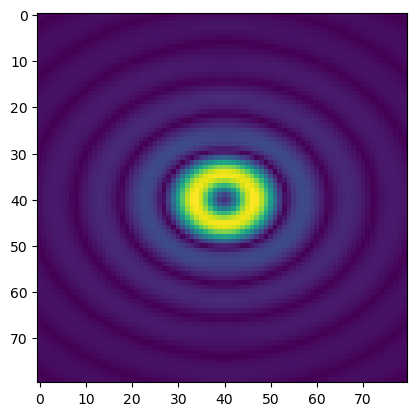

In [128]:
A_input = build_input()
bb_phase = torch.tensor(bottle_beam_phase())
pad_factor = 4
m = SLMphaseRetrievalCG(A_in = A_input,A_t = None,pad_factor=pad_factor)
out = m.build_target_from_phase(bb_phase).abs().numpy()
plt.imshow(out[502*pad_factor:522*pad_factor,630*pad_factor:650*pad_factor])

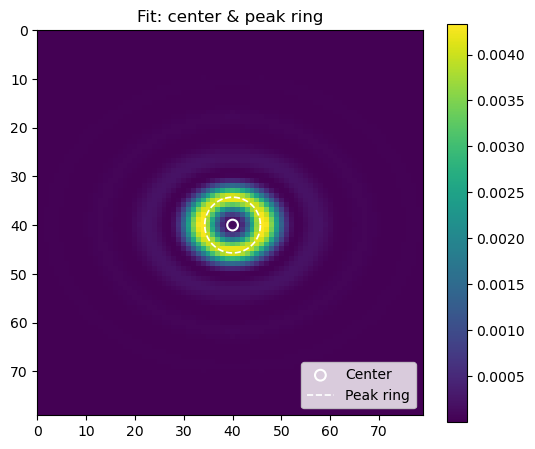

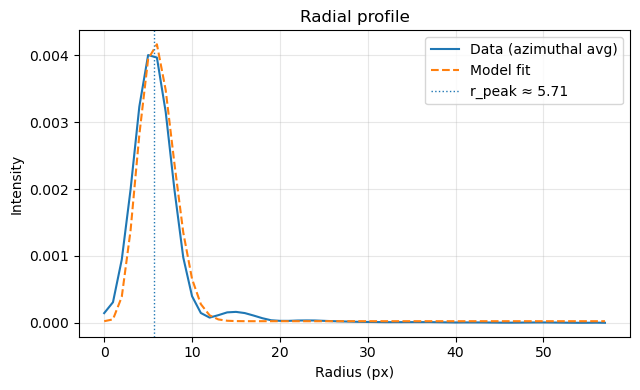

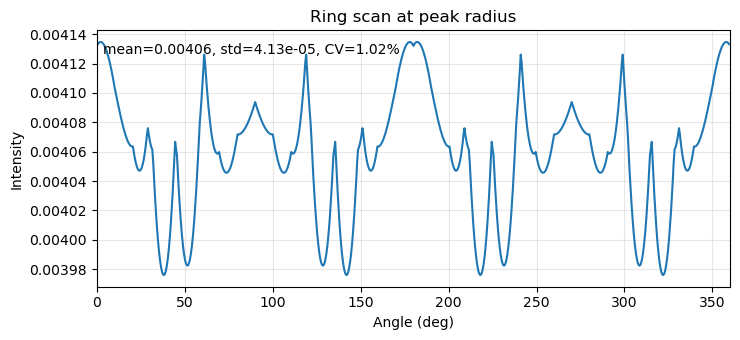

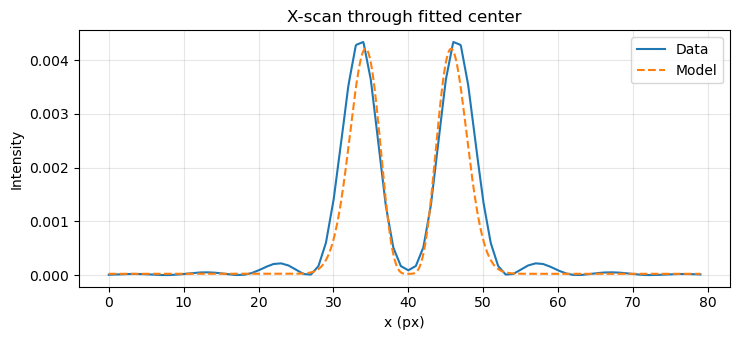

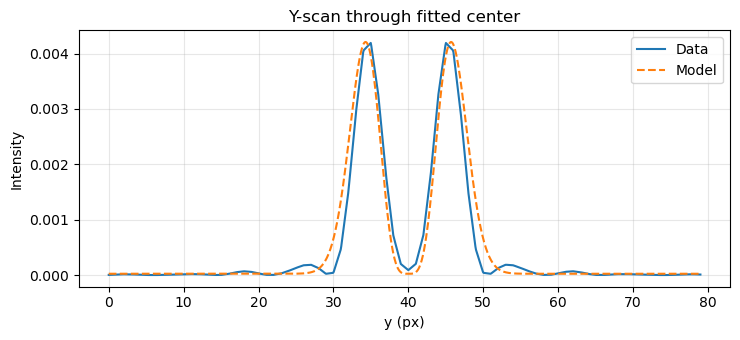

In [129]:
params = fit_bottle_beam(out[502*pad_factor:522*pad_factor,630*pad_factor:650*pad_factor]**2, make_plots=True)

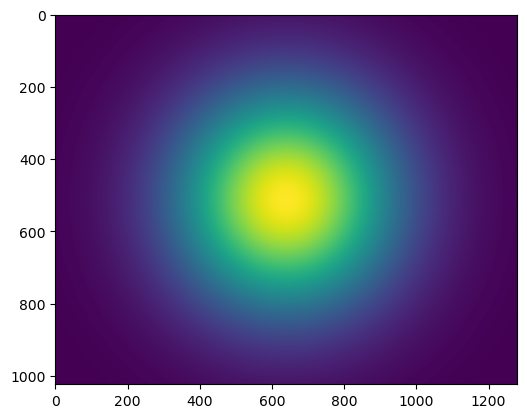

In [130]:
plt.imshow(A_input)

/Users/apple/Desktop/holography/src/gradient.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_in = self.pad(torch.tensor(A_in / FeedbackHologram._norm(A_in), dtype=torch.float32))
/Users/apple/Desktop/holography/src/gradient.py:96: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_t = torch.tensor(target, dtype=torch.float32)


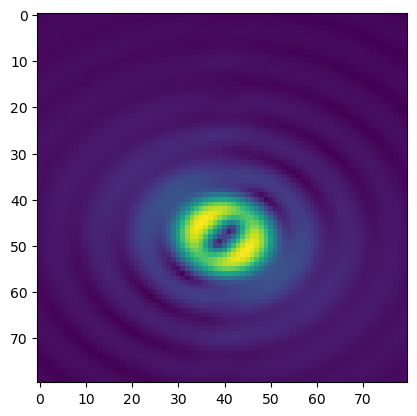

In [131]:
A_input = build_input(xc = 530,yc = 412)
pad_factor = 4
m = SLMphaseRetrievalCG(A_in = A_input,A_t = None,pad_factor=pad_factor)
out = m.build_target_from_phase(bb_phase).abs().numpy()
plt.imshow(out[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

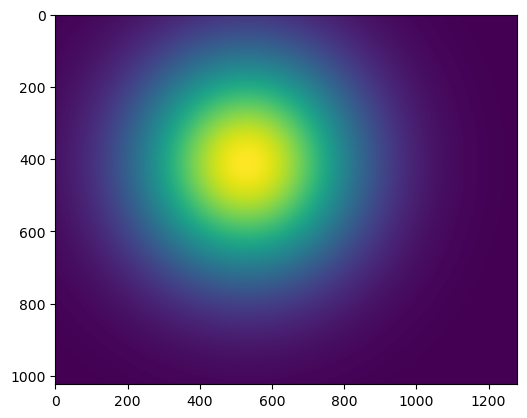

In [132]:
plt.imshow(A_input.numpy())

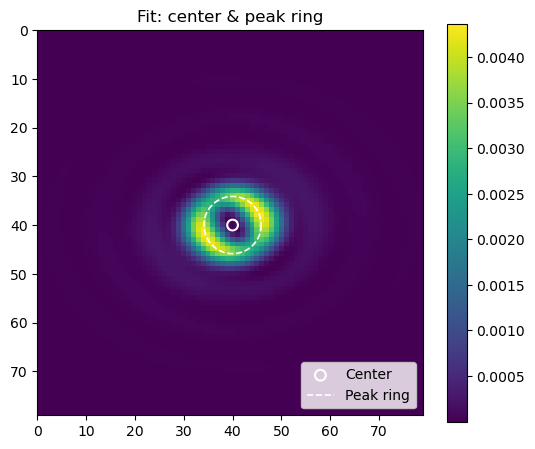

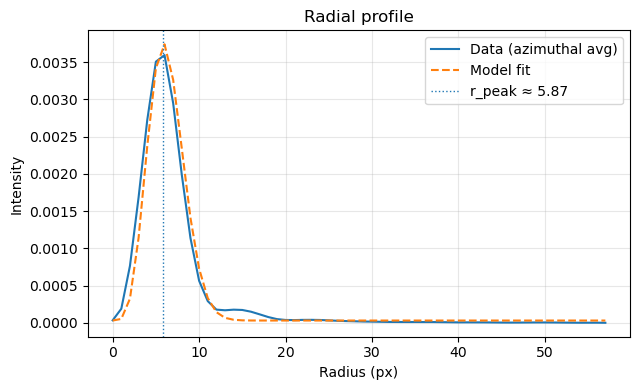

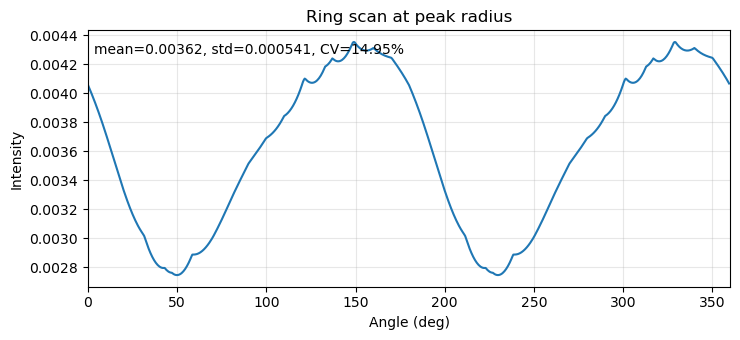

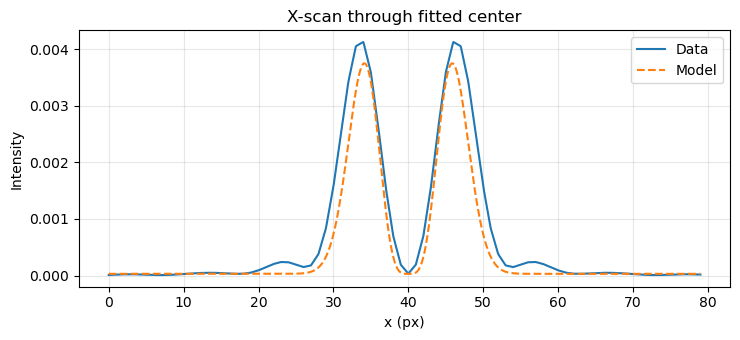

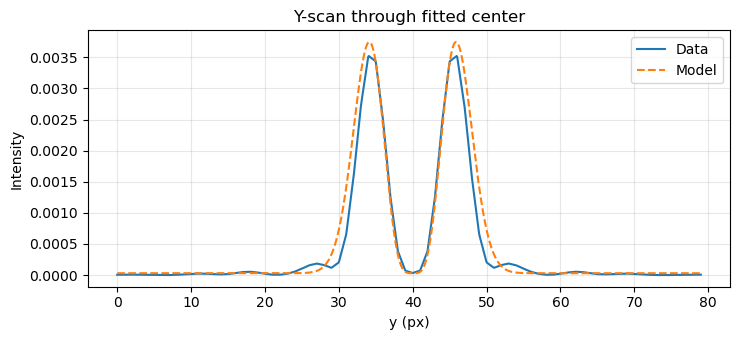

In [121]:
params = fit_bottle_beam(out[502*pad_factor:522*pad_factor,630*pad_factor:650*pad_factor]**2, make_plots=True)

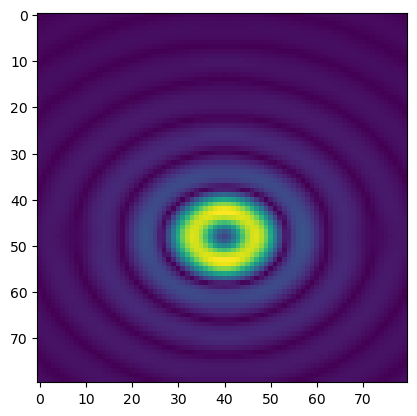

In [123]:
A_input = build_input(xc = 400,yc = 512)
bb_phase = torch.tensor(bottle_beam_phase(xc = 400,yc = 512))
pad_factor = 4
m = SLMphaseRetrievalCG(A_in = A_input,A_t = None,pad_factor=pad_factor)
out = m.build_target_from_phase(bb_phase).abs().numpy()
plt.imshow(out[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

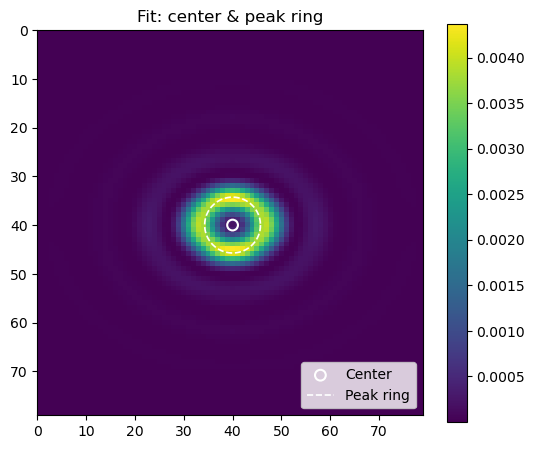

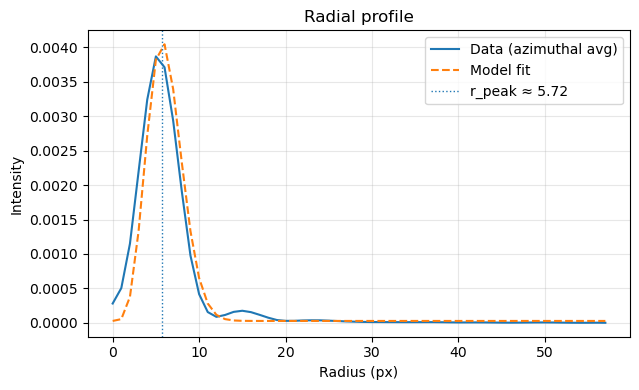

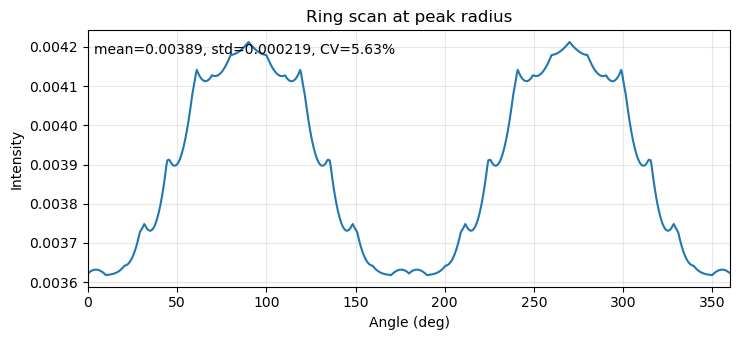

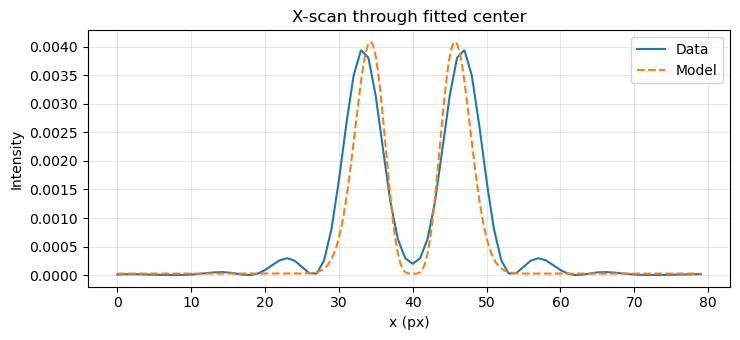

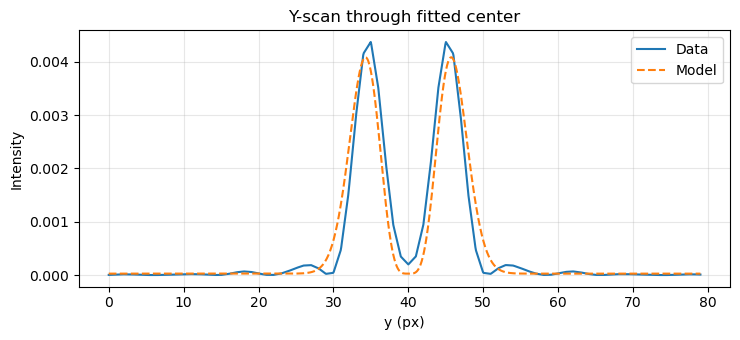

In [124]:
params = fit_bottle_beam(out[502*pad_factor:522*pad_factor,630*pad_factor:650*pad_factor]**2, make_plots=True)

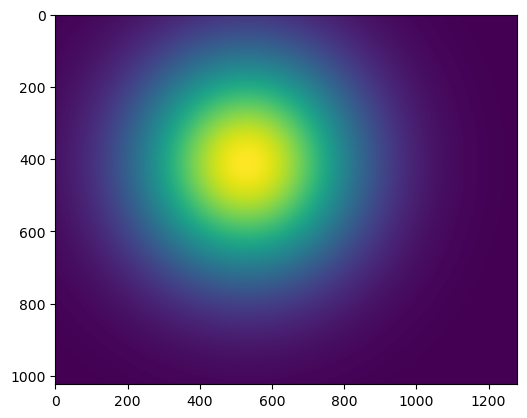

In [122]:
plt.imshow(A_input.numpy())